# Mining comparison on AIT-ADS (plan 7.6, temporal arm)

Same question as notebook 06 (does the mining principle matter?), now on data with an alert order to mine, so all
five methods run:

|  | Label used **after** the search | Label used **during** the search |
|---|---|---|
| **Atemporal** | Eclat | Contrast tree (ours), RIPPER |
| **Temporal** | PrefixSpan | MCTSExtent |

**Protocol: within-scenario 70/30 split (the thesis setup, decided 2026-11-21).** Per scenario, its labelled groups
(cscas_grouping, token arm T2) in time order: the first 70% train, the last 30% test (as in
`baselines/_ait_ads_data.py`, thesis Table 5.9). Scenarios with no attack in their first 70% are skipped (harrison,
russellmitchell, santos), leaving 5 steps. Same kind of test as the CSCAS walk-forward: train on the past of the same
network. (The earlier leave-one-scenario-out runs are a harder, different test; set `PROTOCOL = "loso"` below to
reopen them.) Temporal methods mine per-host look-back
sequences (10 min, 1-min buckets). Same shared treatment as CSCAS: precision gate (benign side relaxed to ≤ π),
condition + near-duplicate dedupe, budget K = 60 per class, class-weighted RF at 0.5, 5 seeds (RIPPER and
MCTSExtent re-mined per seed).

**Main result: without `hour_of_day` (decided 2026-11-22).** AIT-ADS runs its attack scripts at fixed times (fox around
12:00 UTC, wilson's phases at 10:00 UTC), so with `hour_of_day` in the base features the models mostly learn the
attack schedule: without it, no mining falls to chance on both informative scenarios (FINDINGS.md, "AIT-ADS shortcut
checks"). The main run therefore uses 4 base features (`n_alerts`, `n_sigs`, `n_hosts`, `n_shorts`) for every arm;
§10 compares it with the runs that keep the hour and/or drop the host item.

**Testing with 5 steps.** Across 5 scenarios, a Wilcoxon test can't go below p = 0.0625 even when one method wins all
5, and the Friedman / Nemenyi test has little power. The main test here is a **paired bootstrap over the test groups**
within each scenario (§5; `bootstrap.csv`, `thesis.system_eval.score_bootstrap`): 1000 resamples of the test groups,
stratified by class, both arms scored on the same resample, each arm averaged over its seeds; plus the mean over the
scenarios ("all"). A difference is significant when its 95% interval excludes 0 (p not corrected for the number of
pairs).

**Read with the label noise in mind.** AIT-ADS labels everything inside an attack time window as an attack, so
F1 and precision stay low for every arm (FINDINGS.md). Compare on PR-AUC and the helps/hurts counts.

Logic: `thesis.system_eval.mining_comparison`; run with `shell-scripts/paper/run_mining_comparison_ait_ads.sh` (DGX).

In [1]:
from __future__ import annotations

import json
import re
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sps

from thesis.paths import ROOT
from thesis.system_eval import mining_comparison as mc

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

ARMS = ["mctsextent", "prefixspan", "ripper", "contrast_tree", "eclat", "none"]
METHODS = [a for a in ARMS if a != "none"]
LABEL = {"mctsextent": "MCTSExtent", "prefixspan": "PrefixSpan", "ripper": "RIPPER",
         "contrast_tree": "Contrast tree", "eclat": "Eclat", "none": "No mining"}
COLOR = {"mctsextent": "tab:purple", "prefixspan": "tab:red", "ripper": "tab:green",
         "contrast_tree": "tab:blue", "eclat": "tab:orange", "none": "tab:gray"}


def to_booktabs(df: pd.DataFrame, caption: str, label: str, float_fmt: str = "{:.3f}") -> str:
    styler = df.style.hide(axis="index").format(
        {c: float_fmt for c in df.select_dtypes("float").columns}
    ).format_index(escape="latex", axis=1).format(escape="latex-math", subset=df.select_dtypes("object").columns)
    return styler.to_latex(hrules=True, caption=caption, label=label, position="t", position_float="centering")

## Load

In [2]:
PROTOCOL = "split_no_hour"  # main: split without hour_of_day | "split" (with the hour) | "loso"
RUN_DIR = None  # None -> latest finished run of PROTOCOL with the most scenarios, else a path

BASE = {
    "split_no_hour": "mining_comparison_ait_ads_split_no_hour",
    "split": "mining_comparison_ait_ads_split",
    "loso": "mining_comparison_ait_ads",
}[PROTOCOL]


def _latest_full_run() -> Path:
    base = ROOT / "artifacts" / "experiments" / BASE
    runs = [d for d in sorted(base.glob("*")) if (d / "summary.csv").exists()]
    if not runs:
        raise FileNotFoundError(f"no finished run under {base}")
    n_steps = {d: pd.read_csv(d / "per_step_results.csv")["scenario"].nunique() for d in runs}
    best = max(n_steps.values())
    return [d for d in runs if n_steps[d] == best][-1]


run_dir = Path(RUN_DIR) if RUN_DIR else _latest_full_run()
per_step = pd.read_csv(run_dir / "per_step_results.csv")
features = pd.read_csv(run_dir / "features.csv")
windows = pd.read_csv(run_dir / "windows.csv")
skipped = pd.read_csv(run_dir / "skipped.csv") if (run_dir / "skipped.csv").exists() else pd.DataFrame()
boot = pd.read_csv(run_dir / "bootstrap.csv") if (run_dir / "bootstrap.csv").exists() else None
means = mc.per_step_means(per_step)  # seed-averaged, one row per (arm, scenario step)
FOLD = per_step.groupby("step_i")["scenario"].first().rename("scenario")  # step_i -> scenario
N = len(FOLD)
print(run_dir)
_cfgs = [s["config"] for s in json.loads((run_dir / "sources.json").read_text()) if s.get("config")] \
    if (run_dir / "sources.json").exists() else [json.loads((run_dir / "config.json").read_text())]
print("hour_of_day excluded:", all("hour_of_day" in str(c.get("base_exclude_features")) for c in _cfgs),
      "| host excluded:", all("host" in str(c.get("extra_exclude_fields")) for c in _cfgs))
print("scenarios:", list(FOLD), "| skipped:", list(skipped.get("scenario", [])),
      "| rows per arm:", per_step.groupby("arm").size().to_dict(), "| seeds:", sorted(per_step["seed"].unique()))


/Users/annavisman/stack/TUDelft/thesis/msc-thesis/artifacts/experiments/mining_comparison_ait_ads_split_no_hour/20261122_130506
hour_of_day excluded: True | host excluded: False
scenarios: ['fox', 'shaw', 'wardbeck', 'wheeler', 'wilson'] | skipped: ['harrison', 'russellmitchell', 'santos'] | rows per arm: {'contrast_tree': 25, 'eclat': 25, 'mctsextent': 25, 'none': 25, 'prefixspan': 25, 'ripper': 25} | seeds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


### The scenarios

Each step trains on a scenario's first 70% and tests on its last 30%. Skipped scenarios have no attack to learn from
in their training part (all their attacks fall in the last 30%).

In [3]:
folds = windows.assign(test_attack_rate=windows["n_test_attack"] / windows["n_test"])[
    ["scenario", "n_train", "n_train_attack", "n_test", "n_test_attack", "test_attack_rate", "test_days"]
]
display(folds.round(3))
if not skipped.empty:
    display(skipped[["scenario", "n_train", "n_train_attack", "n_test", "n_test_attack", "reason"]])

,scenario,n_train,n_train_attack,n_test,n_test_attack,test_attack_rate,test_days
0,fox,4264,109,1828,157,0.086,1.485
1,shaw,4465,17,1914,77,0.040,1.466
2,wardbeck,5651,14,2423,147,0.061,1.562
3,wheeler,12447,49,5335,182,0.034,1.351
4,wilson,10605,153,4545,280,0.062,1.701


,scenario,n_train,n_train_attack,n_test,n_test_attack,reason
0,harrison,11203,0,4802,727,no training attacks
1,russellmitchell,3150,0,1350,198,no training attacks
2,santos,7730,0,3313,231,no training attacks


## §1 Main table

Mean (± std over scenarios) of the seed-averaged metrics. `mine_seconds` is the whole mine → gate → dedupe step per
seed (the miner alone: `miner_seconds`). Redundancy = share of gated distinct conditions dropped as
near-duplicates. Means over 5 scenarios, of which only fox and wilson carry signal (§2), so read the per-scenario table first.

In [4]:
summary = mc.summarize_comparison(per_step).set_index("arm")
main = pd.DataFrame({
    "PR-AUC": summary["pr_auc_mean"], "PR-AUC sd": summary["pr_auc_std"],
    "F1": summary["f1_mean"], "Precision": summary["precision_mean"], "Recall": summary["recall_mean"],
    "ROC-AUC": summary["auc_mean"], "FP/day": summary["fp_per_day_mean"],
    "Features": summary["n_symbolic_mean"], "Cond./feat.": summary["mean_conditions_mean"],
    "Overlap": summary["overlap_mean"], "Redundancy": summary["redundancy_share_mean"],
    "Mine s": summary["mine_seconds_mean"],
}).reindex(ARMS)
main

,PR-AUC,PR-AUC sd,F1,Precision,Recall,ROC-AUC,FP/day,Features,Cond./feat.,Overlap,Redundancy,Mine s
arm,,,,,,,,,,,,
mctsextent,0.112410,0.126366,0.075240,0.058281,0.113016,0.519204,219.272431,39.96,3.123952,0.163932,0.000000,76.4048
prefixspan,0.056586,0.019911,0.076083,0.051795,0.160781,0.485094,322.274935,38.40,2.742602,0.267403,0.968566,5.4340
ripper,0.058827,0.027680,0.071129,0.047800,0.167645,0.458464,463.869141,3.96,2.248223,0.014713,0.000000,1.6256
contrast_tree,0.060456,0.030889,0.069606,0.045368,0.174114,0.463558,489.726640,22.40,2.005512,0.080891,0.620102,0.4080
eclat,0.061669,0.029029,0.077256,0.050322,0.190650,0.483222,501.667447,19.00,3.175554,0.083576,0.900330,0.5840
none,0.060590,0.023761,0.087685,0.054270,0.264322,0.467268,583.681561,0.00,NaN,NaN,NaN,NaN


In [5]:
latex_main = main.reset_index().rename(columns={"arm": "Method"}).assign(Method=lambda d: d["Method"].map(LABEL))
print(to_booktabs(
    latex_main[["Method", "PR-AUC", "F1", "Precision", "Recall", "FP/day", "Features", "Cond./feat.",
                "Redundancy", "Mine s"]],
    caption=f"Mining comparison on AIT-ADS: within-scenario 70/30 split without hour\\_of\\_day, means over {N} "
            "scenarios and 5 seeds (K = 60, class-weighted RF).",
    label="tab:mining-comparison-ait-ads",
))

\begin{table}[t]
\centering
\caption{Mining comparison on AIT-ADS: within-scenario 70/30 split without hour\_of\_day, means over 5 scenarios and 5 seeds (K = 60, class-weighted RF).}
\label{tab:mining-comparison-ait-ads}
\begin{tabular}{lrrrrrrrrr}
\toprule
Method & PR-AUC & F1 & Precision & Recall & FP/day & Features & Cond./feat. & Redundancy & Mine s \\
\midrule
MCTSExtent & 0.112 & 0.075 & 0.058 & 0.113 & 219.272 & 39.960 & 3.124 & 0.000 & 76.405 \\
PrefixSpan & 0.057 & 0.076 & 0.052 & 0.161 & 322.275 & 38.400 & 2.743 & 0.969 & 5.434 \\
RIPPER & 0.059 & 0.071 & 0.048 & 0.168 & 463.869 & 3.960 & 2.248 & 0.000 & 1.626 \\
Contrast tree & 0.060 & 0.070 & 0.045 & 0.174 & 489.727 & 22.400 & 2.006 & 0.620 & 0.408 \\
Eclat & 0.062 & 0.077 & 0.050 & 0.191 & 501.667 & 19.000 & 3.176 & 0.900 & 0.584 \\
No mining & 0.061 & 0.088 & 0.054 & 0.264 & 583.682 & 0.000 & nan & nan & nan \\
\bottomrule
\end{tabular}
\end{table}



## §2 Per scenario

Seed-averaged PR-AUC and F1 per scenario, and the gain over `none`. A scenario carries signal only if some arm ranks
attacks well above chance (PR-AUC ≥ 2× the test attack rate) and beats flagging every group (F1 above flag-all F1). Helps/hurts counts as in notebook 06.

In [6]:
pr = means.pivot(index="step_i", columns="arm", values="pr_auc").rename(index=FOLD)[ARMS]
pr.index.name, pr.columns.name = "scenario", None
display(pr.round(3))
f1 = means.pivot(index="step_i", columns="arm", values="f1").rename(index=FOLD)[ARMS]
f1.index.name, f1.columns.name = "scenario", None
display(f1.round(3))

# Chance level: PR-AUC of a random score is the test attack rate; F1 = 0 means no attack was flagged.
rate = folds.set_index("scenario")["test_attack_rate"]
signal = pd.DataFrame({
    "test attack rate (chance PR-AUC)": rate,
    "best PR-AUC": pr.max(axis=1),
    "flag-all F1": 2 * rate / (1 + rate),
    "best F1": f1.max(axis=1),
})
# Signal: some arm ranks attacks well above chance and beats flagging everything.
signal["carries signal"] = (signal["best PR-AUC"] >= 2 * rate) & (signal["best F1"] > signal["flag-all F1"])
signal.round(3)

,mctsextent,prefixspan,ripper,contrast_tree,eclat,none
scenario,,,,,,
fox,0.337,0.086,0.103,0.109,0.109,0.096
shaw,0.069,0.040,0.040,0.038,0.043,0.042
wardbeck,0.060,0.061,0.058,0.058,0.062,0.063
wheeler,0.033,0.036,0.032,0.030,0.034,0.035
wilson,0.064,0.059,0.061,0.067,0.059,0.067


,mctsextent,prefixspan,ripper,contrast_tree,eclat,none
scenario,,,,,,
fox,0.238,0.112,0.130,0.119,0.134,0.126
shaw,0.039,0.062,0.024,0.016,0.031,0.053
wardbeck,0.015,0.084,0.058,0.058,0.085,0.097
wheeler,0.008,0.047,0.050,0.043,0.053,0.051
wilson,0.076,0.075,0.094,0.112,0.084,0.112


,test attack rate (chance PR-AUC),best PR-AUC,flag-all F1,best F1,carries signal
scenario,,,,,
fox,0.086,0.337,0.158,0.238,True
shaw,0.040,0.069,0.077,0.062,False
wardbeck,0.061,0.063,0.114,0.097,False
wheeler,0.034,0.036,0.066,0.053,False
wilson,0.062,0.067,0.116,0.112,False


In [7]:
hh = pd.concat([mc.helps_hurts(per_step, m) for m in ("pr_auc", "f1")], ignore_index=True)
hh

,arm,metric,n_steps,mean_delta,median_delta,helps,hurts,ties
0,contrast_tree,pr_auc,5,-0.000134,-0.004549,2,3,0
1,eclat,pr_auc,5,0.001079,-0.000495,2,3,0
2,mctsextent,pr_auc,5,0.051821,-0.002411,2,3,0
3,prefixspan,pr_auc,5,-0.004004,-0.001985,1,4,0
4,ripper,pr_auc,5,-0.001763,-0.002692,1,4,0
5,contrast_tree,f1,5,-0.018079,-0.007826,0,5,0
6,eclat,f1,5,-0.010429,-0.012244,2,3,0
7,mctsextent,f1,5,-0.012445,-0.036628,1,4,0
8,prefixspan,f1,5,-0.011602,-0.013173,1,4,0
9,ripper,f1,5,-0.016556,-0.018685,1,4,0


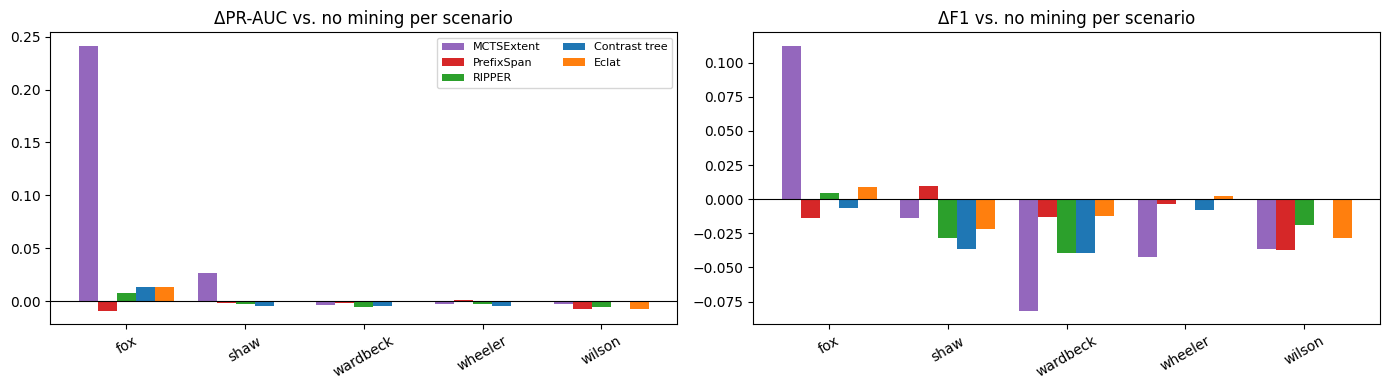

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(pr))
w = 0.16
for ax, m in zip(axes, ("pr_auc", "f1")):
    d = means.pivot(index="step_i", columns="arm", values=m).rename(index=FOLD)
    for j, a in enumerate(METHODS):
        ax.bar(x + (j - 2) * w, d[a] - d["none"], width=w, color=COLOR[a], label=LABEL[a])
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(x, d.index, rotation=30)
    ax.set_title(f"Δ{m.upper().replace('_', '-')} vs. no mining per scenario")
axes[0].legend(fontsize=8, ncol=2)
plt.tight_layout()

## §3 Friedman test + Nemenyi critical difference

Scenarios are the blocks (seed-averaged). Rank 1 = best. With 6 arms and 5 scenarios the CD is very large (~3.4
ranks) and the three scenarios at chance tie every arm, so this has almost no power: shown for completeness, the
bootstrap (§5) is the test.

In [9]:
stats = {m: mc.friedman_nemenyi(per_step, m) for m in ("pr_auc", "f1")}
pd.DataFrame([{"metric": s["metric"], "chi2": s["friedman_chi2"], "p": s["friedman_p"], "CD": s["nemenyi_cd"],
               **{LABEL[a]: r for a, r in s["avg_rank"].items()}} for s in stats.values()])

,metric,chi2,p,CD,MCTSExtent,No mining,Eclat,PrefixSpan,Contrast tree,RIPPER
0,pr_auc,6.485714,0.261781,3.371817,2.6,2.6,2.8,4.0,4.2,4.8
1,f1,6.714286,0.242771,3.371817,4.2,2.0,2.6,4.0,4.4,3.8


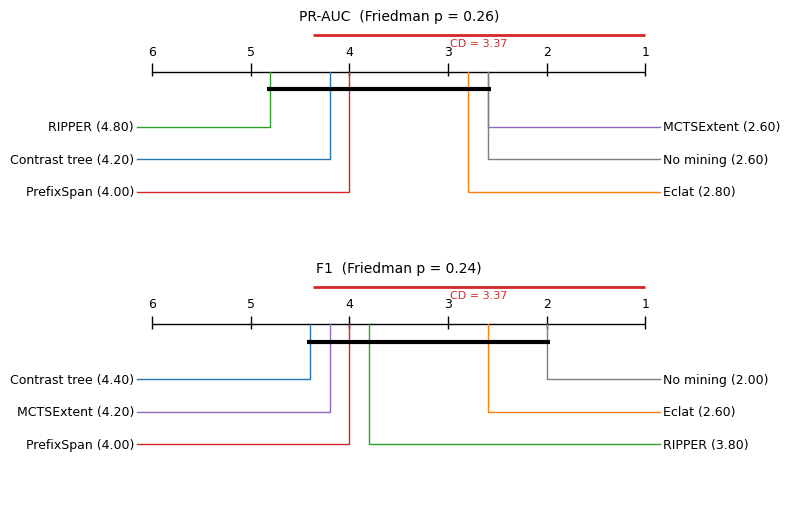

In [10]:
def cd_cliques(ranks: dict[str, float], cd: float) -> list[list[str]]:
    # Maximal groups of arms (in rank order) whose rank span is below CD.
    order = sorted(ranks, key=ranks.get)
    cliques = []
    for i in range(len(order)):
        j = i
        while j + 1 < len(order) and ranks[order[j + 1]] - ranks[order[i]] < cd:
            j += 1
        grp = order[i:j + 1]
        if len(grp) > 1 and not any(set(grp) <= set(c) for c in cliques):
            cliques.append(grp)
    return cliques


def cd_diagram(s: dict, ax) -> None:
    ranks, cd, k = s["avg_rank"], s["nemenyi_cd"], s["n_arms"]
    ax.set_xlim(k + 0.2, 0.8)  # rank 1 on the right
    ax.set_ylim(0, 1)
    ax.axis("off")
    ax.hlines(0.8, 1, k, color="k", lw=1)
    for r in range(1, k + 1):
        ax.vlines(r, 0.78, 0.84, color="k", lw=1)
        ax.text(r, 0.88, str(r), ha="center", fontsize=9)
    ax.hlines(0.97, 1, 1 + cd, color="tab:red", lw=2)
    ax.text(1 + cd / 2, 0.92, f"CD = {cd:.2f}", ha="center", fontsize=8, color="tab:red")
    order = sorted(ranks, key=ranks.get)
    half = (len(order) + 1) // 2
    for i, a in enumerate(order):
        right = i < half  # best arms labelled on the right
        y = 0.55 - 0.15 * (i if right else len(order) - 1 - i)
        xe = 0.85 if right else k + 0.15
        ax.plot([ranks[a], ranks[a], xe], [0.8, y, y], color=COLOR[a], lw=1)
        ax.text(xe + (-0.03 if right else 0.03), y, f"{LABEL[a]} ({ranks[a]:.2f})", va="center",
                ha="left" if right else "right", fontsize=9)
    for n, grp in enumerate(cd_cliques(ranks, cd)):
        lo, hi = min(ranks[a] for a in grp), max(ranks[a] for a in grp)
        ax.hlines(0.72 - 0.05 * n, lo - 0.03, hi + 0.03, color="k", lw=3)
    ax.set_title(f"{s['metric'].upper().replace('_', '-')}  (Friedman p = {s['friedman_p']:.2g})", fontsize=10)



fig, axes = plt.subplots(2, 1, figsize=(8, 5.2))
for ax, s in zip(axes, stats.values()):
    cd_diagram(s, ax)
plt.tight_layout()

## §4 The paper's contrasts, paired over scenarios

Paired over the scenarios (seed-averaged): mean Δ (B − A), scenarios where B beats A, and a Wilcoxon signed-rank
p-value. With 5 scenarios the smallest possible Wilcoxon p is 0.0625, so none can be significant; §5 tests the same
contrasts with the bootstrap.

- **Label after vs. during the search:** Eclat → contrast tree (atemporal), PrefixSpan → MCTSExtent (temporal).
- **Two-step patterns vs. learning a rule set directly:** contrast tree → RIPPER.
- **Atemporal vs. temporal** (both frequency-based, only order differs): Eclat → PrefixSpan.

In [11]:
CONTRASTS = [
    ("label after → during (atemporal)", "eclat", "contrast_tree"),
    ("label after → during (temporal)", "prefixspan", "mctsextent"),
    ("two-step → rule set", "contrast_tree", "ripper"),
    ("atemporal → temporal", "eclat", "prefixspan"),
]


def paired(metric: str) -> pd.DataFrame:
    d = means.pivot(index="step_i", columns="arm", values=metric)
    rows = []
    for name, a, b in CONTRASTS:
        diff = d[b] - d[a]
        rows.append({
            "contrast": name, "A": LABEL[a], "B": LABEL[b], "metric": metric,
            "mean A": d[a].mean(), "mean B": d[b].mean(), "mean Δ (B−A)": diff.mean(),
            "B better (scenarios)": f"{int((diff > 0).sum())}/{len(diff)}",
            "Wilcoxon p": sps.wilcoxon(d[b], d[a]).pvalue if (diff != 0).any() else np.nan,
        })
    return pd.DataFrame(rows)


contrasts = pd.concat([paired("pr_auc"), paired("f1")], ignore_index=True)
contrasts.round(4)

,contrast,A,B,metric,mean A,mean B,mean Δ (B−A),B better (scenarios),Wilcoxon p
0,label after → during (atemporal),Eclat,Contrast tree,pr_auc,0.0617,0.0605,-0.0012,1/5,0.6250
1,label after → during (temporal),PrefixSpan,MCTSExtent,pr_auc,0.0566,0.1124,0.0558,3/5,0.3125
2,two-step → rule set,Contrast tree,RIPPER,pr_auc,0.0605,0.0588,-0.0016,2/5,0.6250
3,atemporal → temporal,Eclat,PrefixSpan,pr_auc,0.0617,0.0566,-0.0051,1/5,0.3125
4,label after → during (atemporal),Eclat,Contrast tree,f1,0.0773,0.0696,-0.0077,1/5,0.6250
5,label after → during (temporal),PrefixSpan,MCTSExtent,f1,0.0761,0.0752,-0.0008,2/5,0.8125
6,two-step → rule set,Contrast tree,RIPPER,f1,0.0696,0.0711,0.0015,3/5,0.8125
7,atemporal → temporal,Eclat,PrefixSpan,f1,0.0773,0.0761,-0.0012,1/5,0.6250


In [12]:
print(to_booktabs(
    contrasts[contrasts["metric"] == "pr_auc"].drop(columns="metric"),
    caption=f"AIT-ADS: the paper's contrasts, paired over {N} scenarios (PR-AUC).",
    label="tab:mining-contrasts-ait-ads",
))

\begin{table}[t]
\centering
\caption{AIT-ADS: the paper's contrasts, paired over 5 scenarios (PR-AUC).}
\label{tab:mining-contrasts-ait-ads}
\begin{tabular}{lllrrrlr}
\toprule
contrast & A & B & mean A & mean B & mean Δ (B−A) & B better (scenarios) & Wilcoxon p \\
\midrule
label after → during (atemporal) & Eclat & Contrast tree & 0.062 & 0.060 & -0.001 & 1/5 & 0.625 \\
label after → during (temporal) & PrefixSpan & MCTSExtent & 0.057 & 0.112 & 0.056 & 3/5 & 0.312 \\
two-step → rule set & Contrast tree & RIPPER & 0.060 & 0.059 & -0.002 & 2/5 & 0.625 \\
atemporal → temporal & Eclat & PrefixSpan & 0.062 & 0.057 & -0.005 & 1/5 & 0.312 \\
\bottomrule
\end{tabular}
\end{table}



## §5 Paired bootstrap over test groups

Per scenario: Δ = B − A on the full test set, its 95% bootstrap interval and p (1000 resamples, stratified by class,
same resample for both arms, each arm the mean over its seeds). "all" = the mean Δ over the scenarios, with the
scenarios fixed and the test groups resampled. ★ = the interval excludes 0.

### Each method vs. no mining

In [13]:
if boot is None:
    raise FileNotFoundError(f"{run_dir}: no bootstrap.csv (run predates saved test scores)")
ORDER = list(FOLD) + ["all"]


def oriented(a: str, b: str, metric: str) -> pd.DataFrame:
    """Bootstrap rows for B − A (flipping the stored a − b when needed)."""
    m = boot[boot["metric"] == metric]
    fwd = m[(m["a"] == b) & (m["b"] == a)]
    if not fwd.empty:
        return fwd.set_index("scenario")
    rev = m[(m["a"] == a) & (m["b"] == b)].set_index("scenario").copy()
    rev["delta"], rev["ci_low"], rev["ci_high"] = -rev["delta"], -rev["ci_high"], -rev["ci_low"]
    return rev


def cell(r) -> str:
    return f"{r['delta']:+.3f} [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]{' ★' if r['significant'] else ''}"


def vs_none(metric: str) -> pd.DataFrame:
    return pd.DataFrame(
        {LABEL[a]: oriented("none", a, metric).reindex(ORDER).apply(cell, axis=1) for a in METHODS}
    ).T[ORDER]


for metric in ("pr_auc", "f1"):
    print(f"\nΔ{metric.upper()} vs. no mining  (Δ [95% CI], ★ = excludes 0)")
    display(vs_none(metric))


ΔPR_AUC vs. no mining  (Δ [95% CI], ★ = excludes 0)


scenario,fox,shaw,wardbeck,wheeler,wilson,all
MCTSExtent,"+0.242 [+0.172, +0.306] ★","+0.026 [+0.003, +0.052] ★","-0.003 [-0.017, +0.003]","-0.002 [-0.012, +0.003]","-0.003 [-0.011, +0.004]","+0.052 [+0.037, +0.065] ★"
PrefixSpan,"-0.009 [-0.044, +0.018]","-0.002 [-0.015, +0.003]","-0.002 [-0.009, +0.002]","+0.001 [-0.006, +0.007]","-0.008 [-0.016, -0.001] ★","-0.004 [-0.012, +0.002]"
RIPPER,"+0.008 [-0.011, +0.029]","-0.003 [-0.018, +0.006]","-0.006 [-0.017, +0.000]","-0.003 [-0.009, +0.001]","-0.006 [-0.010, -0.002] ★","-0.002 [-0.007, +0.003]"
Contrast tree,"+0.013 [-0.011, +0.045]","-0.005 [-0.027, +0.002]","-0.005 [-0.018, +0.001]","-0.005 [-0.014, +0.000]","+0.000 [-0.003, +0.003]","-0.000 [-0.007, +0.006]"
Eclat,"+0.014 [+0.001, +0.028] ★","+0.000 [-0.005, +0.003]","-0.001 [-0.005, +0.002]","-0.000 [-0.006, +0.003]","-0.007 [-0.013, -0.003] ★","+0.001 [-0.002, +0.004]"



ΔF1 vs. no mining  (Δ [95% CI], ★ = excludes 0)


scenario,fox,shaw,wardbeck,wheeler,wilson,all
MCTSExtent,"+0.113 [+0.061, +0.163] ★","-0.014 [-0.038, +0.009]","-0.082 [-0.114, -0.049] ★","-0.042 [-0.058, -0.027] ★","-0.037 [-0.057, -0.015] ★","-0.012 [-0.028, +0.002]"
PrefixSpan,"-0.014 [-0.047, +0.019]","+0.010 [-0.002, +0.021]","-0.013 [-0.037, +0.010]","-0.003 [-0.024, +0.018]","-0.037 [-0.055, -0.018] ★","-0.012 [-0.022, -0.001] ★"
RIPPER,"+0.005 [-0.016, +0.026]","-0.028 [-0.048, -0.010] ★","-0.040 [-0.071, -0.013] ★","-0.001 [-0.010, +0.009]","-0.019 [-0.029, -0.010] ★","-0.017 [-0.025, -0.008] ★"
Contrast tree,"-0.007 [-0.034, +0.017]","-0.037 [-0.057, -0.017] ★","-0.039 [-0.074, -0.006] ★","-0.008 [-0.018, +0.003]","-0.000 [-0.009, +0.008]","-0.018 [-0.029, -0.009] ★"
Eclat,"+0.009 [-0.009, +0.026]","-0.022 [-0.045, -0.002] ★","-0.012 [-0.039, +0.014]","+0.002 [-0.009, +0.013]","-0.029 [-0.043, -0.016] ★","-0.010 [-0.019, -0.003] ★"


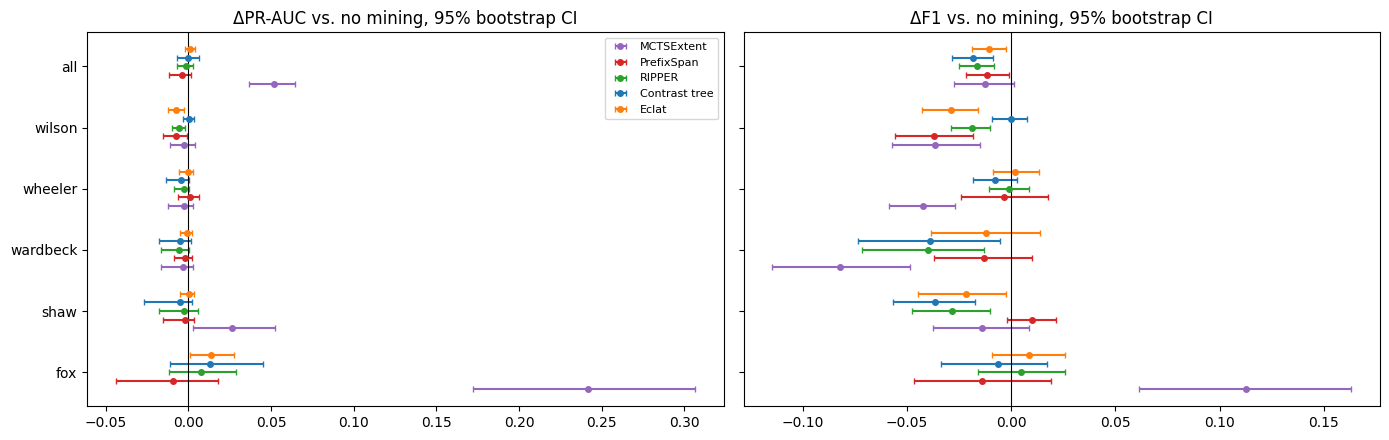

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, metric in zip(axes, ("pr_auc", "f1")):
    for j, a in enumerate(METHODS):
        r = oriented("none", a, metric).reindex(ORDER)
        y = np.arange(len(ORDER)) + (j - 2) * 0.14
        ax.errorbar(r["delta"], y, xerr=[r["delta"] - r["ci_low"], r["ci_high"] - r["delta"]],
                    fmt="o", ms=4, color=COLOR[a], label=LABEL[a], capsize=2)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(np.arange(len(ORDER)), ORDER)
    ax.invert_yaxis()
    ax.set_title(f"Δ{metric.upper().replace('_', '-')} vs. no mining, 95% bootstrap CI")
axes[0].legend(fontsize=8)
plt.tight_layout()

### The paper's contrasts

In [15]:
rows = []
for name, a, b in CONTRASTS:
    for metric in ("pr_auc", "f1"):
        r = oriented(a, b, metric).reindex(ORDER)
        rows.append({"contrast": name, "A → B": f"{LABEL[a]} → {LABEL[b]}", "metric": metric,
                     **{s: cell(r.loc[s]) for s in ORDER}})
boot_contrasts = pd.DataFrame(rows)
boot_contrasts

,contrast,A → B,metric,fox,shaw,wardbeck,wheeler,wilson,all
0,label after → during (atemporal),Eclat → Contrast tree,pr_auc,"-0.000 [-0.027, +0.035]","-0.005 [-0.024, +0.000]","-0.004 [-0.015, +0.001]","-0.004 [-0.011, -0.001] ★","+0.008 [+0.004, +0.013] ★","-0.001 [-0.008, +0.006]"
1,label after → during (atemporal),Eclat → Contrast tree,f1,"-0.015 [-0.050, +0.017]","-0.015 [-0.034, +0.000]","-0.027 [-0.052, -0.001] ★","-0.010 [-0.021, +0.000]","+0.029 [+0.016, +0.042] ★","-0.008 [-0.018, +0.002]"
2,label after → during (temporal),PrefixSpan → MCTSExtent,pr_auc,"+0.251 [+0.186, +0.313] ★","+0.028 [+0.002, +0.063] ★","-0.001 [-0.011, +0.003]","-0.003 [-0.010, -0.000] ★","+0.005 [-0.002, +0.010]","+0.056 [+0.041, +0.069] ★"
3,label after → during (temporal),PrefixSpan → MCTSExtent,f1,"+0.127 [+0.076, +0.175] ★","-0.024 [-0.050, +0.001]","-0.069 [-0.104, -0.038] ★","-0.039 [-0.058, -0.021] ★","+0.000 [-0.018, +0.018]","-0.001 [-0.015, +0.013]"
4,two-step → rule set,Contrast tree → RIPPER,pr_auc,"-0.005 [-0.033, +0.016]","+0.002 [-0.001, +0.014]","-0.001 [-0.003, +0.001]","+0.002 [-0.000, +0.005]","-0.006 [-0.010, -0.003] ★","-0.002 [-0.007, +0.004]"
5,two-step → rule set,Contrast tree → RIPPER,f1,"+0.011 [-0.009, +0.036]","+0.009 [+0.002, +0.018] ★","-0.001 [-0.023, +0.021]","+0.007 [+0.002, +0.014] ★","-0.019 [-0.029, -0.009] ★","+0.002 [-0.006, +0.009]"
6,atemporal → temporal,Eclat → PrefixSpan,pr_auc,"-0.023 [-0.060, +0.010]","-0.002 [-0.013, +0.004]","-0.001 [-0.007, +0.003]","+0.002 [-0.004, +0.007]","-0.000 [-0.007, +0.006]","-0.005 [-0.013, +0.002]"
7,atemporal → temporal,Eclat → PrefixSpan,f1,"-0.023 [-0.059, +0.010]","+0.032 [+0.008, +0.058] ★","-0.001 [-0.029, +0.033]","-0.005 [-0.026, +0.017]","-0.008 [-0.025, +0.008]","-0.001 [-0.012, +0.011]"


In [16]:
tab = vs_none("pr_auc").reset_index().rename(columns={"index": "Method"})
print(to_booktabs(
    tab,
    caption=f"AIT-ADS: ΔPR-AUC over no mining per scenario (70/30 split, no hour\\_of\\_day), with 95\\% paired bootstrap intervals "
            "over test groups (1000 resamples); ★ = interval excludes 0; all = mean over scenarios.",
    label="tab:mining-bootstrap-ait-ads",
))

\begin{table}[t]
\centering
\caption{AIT-ADS: ΔPR-AUC over no mining per scenario (70/30 split, no hour\_of\_day), with 95\% paired bootstrap intervals over test groups (1000 resamples); ★ = interval excludes 0; all = mean over scenarios.}
\label{tab:mining-bootstrap-ait-ads}
\begin{tabular}{lllllll}
\toprule
Method & fox & shaw & wardbeck & wheeler & wilson & all \\
\midrule
MCTSExtent & +0.242 [+0.172, +0.306] ★ & +0.026 [+0.003, +0.052] ★ & -0.003 [-0.017, +0.003] & -0.002 [-0.012, +0.003] & -0.003 [-0.011, +0.004] & +0.052 [+0.037, +0.065] ★ \\
PrefixSpan & -0.009 [-0.044, +0.018] & -0.002 [-0.015, +0.003] & -0.002 [-0.009, +0.002] & +0.001 [-0.006, +0.007] & -0.008 [-0.016, -0.001] ★ & -0.004 [-0.012, +0.002] \\
RIPPER & +0.008 [-0.011, +0.029] & -0.003 [-0.018, +0.006] & -0.006 [-0.017, +0.000] & -0.003 [-0.009, +0.001] & -0.006 [-0.010, -0.002] ★ & -0.002 [-0.007, +0.003] \\
Contrast tree & +0.013 [-0.011, +0.045] & -0.005 [-0.027, +0.002] & -0.005 [-0.018, +0.001] & -0.005 [-0.

## §6 Seed noise

Std over seeds within a scenario, averaged over scenarios. Eclat, the contrast tree and PrefixSpan are mined once per scenario,
so their spread is the RF seed only; RIPPER and MCTSExtent are re-mined per seed.

In [17]:
seed_sd = (per_step.groupby(["arm", "step_i"])[["pr_auc", "f1", "n_symbolic"]].std()
           .groupby("arm").mean().reindex(ARMS))
seed_sd.columns = [f"{c} seed-sd" for c in seed_sd.columns]
seed_sd

,pr_auc seed-sd,f1 seed-sd,n_symbolic seed-sd
arm,,,
mctsextent,0.003639,0.004158,0.962580
prefixspan,0.000810,0.003373,0.000000
ripper,0.003300,0.009400,1.185123
contrast_tree,0.000607,0.003229,0.000000
eclat,0.001676,0.003233,0.000000
none,0.001232,0.001995,0.000000


## §7 What the features look like

Seed 0 for the stochastic miners. Attack- vs. benign-leaning features per scenario, and the number of conditions
(steps for sequences, items for itemsets and rules).

In [18]:
f0 = features[features["mining_seed"] == features.groupby("arm")["mining_seed"].transform("min")]
lean = (f0.groupby(["arm", "step_i", "source_label"]).size().unstack(fill_value=0)
        .groupby("arm").mean().reindex(METHODS))
lean.columns = [f"{c} / scenario" for c in lean.columns]
cond = (f0.groupby(["arm", "n_conditions"]).size().unstack(fill_value=0)
        .pipe(lambda d: d.div(d.sum(axis=1), axis=0)).reindex(METHODS))
cond.columns = [f"{c} cond." for c in cond.columns]
lean.join(cond).round(3)

,attack / scenario,benign / scenario,1 cond.,2 cond.,3 cond.,4 cond.,5 cond.,6 cond.,7 cond.,8 cond.,9 cond.,10 cond.,11 cond.,13 cond.
arm,,,,,,,,,,,,,,
mctsextent,15.0,25.0,0.315,0.245,0.170,0.060,0.025,0.025,0.03,0.035,0.05,0.03,0.005,0.01
prefixspan,9.4,29.0,0.000,0.219,0.781,0.000,0.000,0.000,0.00,0.000,0.00,0.00,0.000,0.00
ripper,2.0,2.2,0.333,0.524,0.048,0.095,0.000,0.000,0.00,0.000,0.00,0.00,0.000,0.00
contrast_tree,12.2,10.2,0.348,0.518,0.054,0.080,0.000,0.000,0.00,0.000,0.00,0.00,0.000,0.00
eclat,2.0,17.0,0.000,0.063,0.684,0.253,0.000,0.000,0.00,0.000,0.00,0.00,0.000,0.00


### Agreement between scenarios

How many scenarios keep each condition, and the mean pairwise Jaccard of the scenarios' condition sets per method.
Each scenario is mined on its own network, so low agreement is expected; a condition kept in several scenarios is a
pattern that transfers.

In [19]:
sets = f0.groupby(["arm", "step_i"])["condition"].apply(set)
agree = {}
for a in METHODS:
    s = sets.loc[a]
    pairs = [len(s[i] & s[j]) / len(s[i] | s[j]) for i, j in combinations(s.index, 2) if s[i] | s[j]]
    agree[LABEL[a]] = np.mean(pairs) if pairs else np.nan
pd.Series(agree, name="mean pairwise Jaccard of kept conditions between folds").round(3)

MCTSExtent       0.021
PrefixSpan       0.041
RIPPER           0.000
Contrast tree    0.064
Eclat            0.066
Name: mean pairwise Jaccard of kept conditions between folds, dtype: float64

In [20]:
TOP = 6
persist = (f0.groupby(["arm", "condition", "source_label"])["step_i"].nunique()
           .rename("scenarios").reset_index().sort_values(["arm", "scenarios"], ascending=[True, False]))
for a in METHODS:
    print(f"\n== {LABEL[a]} ==")
    top = persist[persist["arm"] == a].head(TOP)
    for _, r in top.iterrows():
        c = r["condition"] if len(r["condition"]) <= 110 else r["condition"][:107] + "..."
        print(f"  {r['scenarios']} scen.  {r['source_label']:<7} {c}")


== MCTSExtent ==
  3 scen.  attack  short:A-Aud-Com4 & short_cat:A-Aud & short_family:audit & short_src:A
  3 scen.  attack  short_src:A
  3 scen.  benign  sig_family:dns
  2 scen.  benign  short:S-Tls-Hnd & short:S-Tls-Rec & short:W-All-Evt & short:W-All-Mul1 & short:W-All-Mul2 & short_cat:S-Tls...
  2 scen.  benign  short:S-Tls-Hnd & short:S-Tls-Rec & short:W-All-Evt & short:W-All-Mul1 & short_cat:S-Tls & short_cat:W-All ...
  2 scen.  benign  short_cat:A-Dns

== PrefixSpan ==
  4 scen.  benign  short_src:W -> short_src:W -> sig_family:tls
  3 scen.  benign  short_src:W -> short_src:W -> short_src:W
  3 scen.  benign  short_src:W -> sig_family:tls -> short_src:W
  2 scen.  benign  short:S-Tls-Hnd -> short:S-Tls-Hnd -> short:W-All-Mul1
  2 scen.  benign  short:W-All-Evt -> short:S-Tls-Hnd -> short_family:dns
  2 scen.  benign  short:W-All-Evt -> short:W-All-Mul1 -> short:W-All-Evt

== RIPPER ==
  1 scen.  attack  NOT_host=inet-dns ∧ short=A-Dns-Clc1
  1 scen.  benign  NOT_host=mail ∧

### Which token levels each method leans on

Share of a method's kept conditions that mention each token level (T2 arm): the full code (`short`, `sig`), the
coarse levels (`short_src`, `short_cat`, `short_family`, `sig_family`) and the other fields (host, alert count, ...).

In [21]:
def token_levels(cond: str) -> set[str]:
    out = set()
    for tok in re.split(r" -> | & | ∧ ", cond):
        tok = tok.strip().removeprefix("NOT_")
        out.add(re.split(r":|<=|>=|<|>|=|_gt_|_le_", tok)[0])
    return out


lv = f0.assign(level=f0["condition"].map(token_levels)).explode("level")
level_share = (lv.groupby(["arm", "level"]).size().div(f0.groupby("arm").size(), level="arm")
               .unstack("arm").reindex(columns=METHODS).fillna(0))
level_share.sort_values("mctsextent", ascending=False).round(3).head(15)

arm,mctsextent,prefixspan,ripper,contrast_tree,eclat
level,,,,,
short_src,0.815,0.328,0.143,0.196,0.347
short,0.800,0.729,0.524,0.259,0.242
short_cat,0.790,0.130,0.143,0.179,0.526
short_family,0.790,0.208,0.000,0.089,0.326
sig_family,0.675,0.193,0.048,0.134,0.242
alert_count,0.000,0.000,0.238,0.134,0.516
host,0.000,0.000,0.524,0.723,0.516
sig,0.000,0.000,0.048,0.116,0.137


## §8 Cost vs. score

Mining time per seed (whole mine → gate → dedupe step, mean over scenarios) against PR-AUC. Log scale on time.

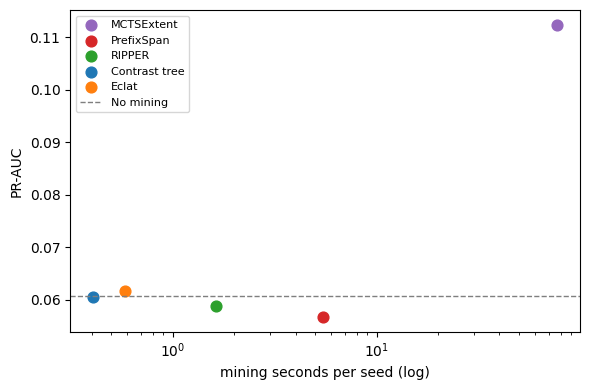

In [22]:
fig, ax = plt.subplots(figsize=(6, 4))
for a in METHODS:
    ax.scatter(main.loc[a, "Mine s"], main.loc[a, "PR-AUC"], s=60, color=COLOR[a], label=LABEL[a])
ax.axhline(main.loc["none", "PR-AUC"], color=COLOR["none"], ls="--", lw=1, label="No mining")
ax.set_xscale("log"); ax.set_xlabel("mining seconds per seed (log)"); ax.set_ylabel("PR-AUC")
ax.legend(fontsize=8); plt.tight_layout()

## §9 Label-noise context

Precision and false positives per day per scenario: every arm flags many benign groups, because the same
alert names occur as attacks inside attack windows and as benign outside them.

In [23]:
ctx = (means.pivot(index="step_i", columns="arm", values="fp_per_day").rename(index=FOLD)[ARMS].round(0)
       .join(folds.set_index("scenario")["test_attack_rate"].round(3)))
ctx.index.name, ctx.columns.name = "scenario", None
ctx

,mctsextent,prefixspan,ripper,contrast_tree,eclat,none,test_attack_rate
scenario,,,,,,,
fox,145.0,220.0,213.0,259.0,250.0,328.0,0.086
shaw,183.0,338.0,211.0,206.0,211.0,458.0,0.040
wardbeck,72.0,217.0,186.0,182.0,234.0,244.0,0.061
wheeler,326.0,435.0,1026.0,1045.0,1142.0,995.0,0.034
wilson,370.0,402.0,683.0,757.0,671.0,894.0,0.062


## §10 Shortcut checks: hour of day and host

The same comparison with and without `hour_of_day` in the base features and the `host` item in the item table
(launcher `NO_HOUR=1` / `NO_HOST=1`). Chance PR-AUC = the test attack share. Only fox and wilson are shown: the
other three scenarios are at chance in every variant.

In [24]:
EXP = ROOT / "artifacts" / "experiments"


def _latest(base: str) -> Path | None:
    runs = [d for d in sorted((EXP / base).glob("*")) if (d / "summary.csv").exists()]
    return runs[-1] if runs else None


VARIANTS = {
    "with hour": _latest("mining_comparison_ait_ads_split"),
    "with hour, no host": _latest("mining_comparison_ait_ads_split_no_host"),
    "no hour (main)": _latest("mining_comparison_ait_ads_split_no_hour"),
    "no hour, no host": _latest("mining_comparison_ait_ads_split_no_host_no_hour"),
}
VARIANTS = {k: v for k, v in VARIANTS.items() if v is not None}
rows = []
for name, d in VARIANTS.items():
    ps = pd.read_csv(d / "per_step_results.csv")
    m = mc.per_step_means(ps)
    m["scenario"] = m["step_i"].map(ps.groupby("step_i")["scenario"].first())
    for metric in ("pr_auc", "f1"):
        for s in ("fox", "wilson"):
            r = m[m["scenario"] == s].set_index("arm")[metric]
            rows.append({"metric": metric, "scenario": s, "variant": name, **{LABEL[a]: r.get(a) for a in ARMS}})
shortcut = pd.DataFrame(rows).set_index(["metric", "scenario", "variant"])
chance = folds.set_index("scenario")["test_attack_rate"]
print("chance PR-AUC:", chance.loc[["fox", "wilson"]].round(3).to_dict())
shortcut.round(3)

chance PR-AUC: {'fox': 0.086, 'wilson': 0.062}


MCTSExtent  PrefixSpan  RIPPER  Contrast tree  Eclat  No mining
metric scenario variant                                                                            
pr_auc fox      with hour                0.384       0.292   0.258          0.267  0.307      0.296
       wilson   with hour                0.318       0.250   0.324          0.352  0.327      0.341
f1     fox      with hour                0.348       0.213   0.278          0.336  0.312      0.315
       wilson   with hour                0.190       0.281   0.424          0.444  0.404      0.448
pr_auc fox      with hour, no host       0.384       0.292   0.271          0.286  0.267      0.296
       wilson   with hour, no host       0.318       0.250   0.347          0.349  0.357      0.341
f1     fox      with hour, no host       0.348       0.213   0.308          0.326  0.310      0.315
       wilson   with hour, no host       0.190       0.281   0.443          0.449  0.463      0.448
pr_auc fox      no hour (main)           0.337       0.086   0.103          0.109  0.109      0.096
       wilson   no hour (main)           0.064       0.059   0.061          0.067  0.059      0.067
f1     fox      no hour (main)           0.238       0.112   0.130          0.119  0.134      0.126
       wilson   no hour (main)           0.076       0.075   0.094          0.112  0.084      0.112
pr_auc fox      no hour, no host         0.337       0.086   0.121          0.116  0.101      0.096
       wilson   no hour, no host         0.064       0.059   0.064          0.067  0.064      0.067
f1     fox      no hour, no host         0.238       0.112   0.139          0.120  0.126      0.126
       wilson   no hour, no host         0.076       0.075   0.112          0.112  0.112      0.112

In [25]:
def boot_vs_none(d: Path, metric: str) -> pd.Series:
    b = pd.read_csv(d / "bootstrap.csv")
    b = b[(b["metric"] == metric) & ((b["a"] == "none") | (b["b"] == "none"))]
    out = {}
    for _, r in b[b["scenario"].isin(["fox", "wilson", "all"])].iterrows():
        flip = r["a"] == "none"
        arm = r["b"] if flip else r["a"]
        dl = -r["delta"] if flip else r["delta"]
        out[(LABEL[arm], r["scenario"])] = f"{dl:+.3f}{' ★' if r['significant'] else ''}"
    return pd.Series(out)


for metric in ("pr_auc", "f1"):
    print(f"\nΔ{metric.upper()} vs. no mining (bootstrap, ★ = 95% CI excludes 0)")
    display(pd.DataFrame({k: boot_vs_none(v, metric) for k, v in VARIANTS.items()}).sort_index())


ΔPR_AUC vs. no mining (bootstrap, ★ = 95% CI excludes 0)


with hour with hour, no host no hour (main) no hour, no host
Contrast tree all       -0.004             -0.000         -0.000           +0.001
              fox     -0.029 ★             -0.010         +0.013           +0.020
              wilson    +0.010           +0.008 ★         +0.000         -0.000 ★
Eclat         all       -0.001             -0.003         +0.001           -0.001
              fox       +0.011           -0.029 ★       +0.014 ★           +0.006
              wilson    -0.014             +0.016       -0.007 ★           -0.003
MCTSExtent    all     +0.021 ★           +0.021 ★       +0.052 ★         +0.052 ★
              fox     +0.089 ★           +0.089 ★       +0.242 ★         +0.242 ★
              wilson    -0.024             -0.024         -0.003           -0.003
PrefixSpan    all     -0.019 ★           -0.019 ★         -0.004           -0.004
              fox       -0.003             -0.003         -0.009           -0.009
              wilson  -0.092 ★           -0.092 ★       -0.008 ★         -0.008 ★
RIPPER        all     -0.011 ★             -0.004         -0.002           +0.003
              fox     -0.038 ★           -0.025 ★         +0.008         +0.025 ★
              wilson  -0.017 ★             +0.006       -0.006 ★         -0.003 ★


ΔF1 vs. no mining (bootstrap, ★ = 95% CI excludes 0)


with hour with hour, no host no hour (main) no hour, no host
Contrast tree all       +0.003             +0.002       -0.018 ★         -0.020 ★
              fox     +0.021 ★             +0.010         -0.007           -0.006
              wilson    -0.004             +0.000         -0.000           -0.000
Eclat         all     -0.010 ★             +0.002       -0.010 ★           -0.005
              fox       -0.003             -0.005         +0.009           +0.000
              wilson  -0.045 ★             +0.015       -0.029 ★           -0.000
MCTSExtent    all     -0.045 ★           -0.045 ★         -0.012           -0.012
              fox       +0.032             +0.032       +0.113 ★         +0.113 ★
              wilson  -0.258 ★           -0.258 ★       -0.037 ★         -0.037 ★
PrefixSpan    all     -0.054 ★           -0.054 ★       -0.012 ★         -0.012 ★
              fox     -0.102 ★           -0.102 ★         -0.014           -0.014
              wilson  -0.168 ★           -0.168 ★       -0.037 ★         -0.037 ★
RIPPER        all     -0.012 ★             -0.003       -0.017 ★         -0.011 ★
              fox     -0.037 ★             -0.007         +0.005           +0.013
              wilson  -0.024 ★             -0.005       -0.019 ★           -0.000

## §11 Settings check without the hour

The main run uses each method's default mining settings. The same split (no `hour_of_day`) rerun with every method at
its low and high setting (`SETTINGS_VARIANT=low|high`). `range` = best − worst over the three settings of the mean
over scenarios; then Δ vs. no mining from the bootstrap, per setting.

In [26]:
SWEEP = sorted((EXP / "mining_settings_sweep" / "ait_ads_split_no_hour").glob("*"))[-1]
SETTING_RUNS = {k: ROOT / v for k, v in json.loads((SWEEP / "settings_runs.json").read_text()).items()}
spread = pd.read_csv(SWEEP / "settings_spread.csv")
print(SWEEP)
for k, v in SETTING_RUNS.items():
    print(f"  {k}: {v.name}")
(spread.assign(arm=spread["arm"].map(LABEL)).set_index(["metric", "arm"])[["low", "default", "high", "range"]]
 .sort_index().round(4))

/Users/annavisman/stack/TUDelft/thesis/msc-thesis/artifacts/experiments/mining_settings_sweep/ait_ads_split_no_hour/20261122
  default: 20261122_130506
  low: 20261122_135746
  high: 20261122_141121


low  default    high   range
metric arm                                           
f1     Contrast tree  0.0696   0.0696  0.0696  0.0000
       Eclat          0.0823   0.0773  0.0771  0.0052
       MCTSExtent     0.0758   0.0752  0.0744  0.0013
       No mining      0.0877   0.0877  0.0877     NaN
       PrefixSpan     0.0761   0.0761  0.0731  0.0031
       RIPPER         0.0732   0.0711  0.0741  0.0030
pr_auc Contrast tree  0.0604   0.0605  0.0605  0.0000
       Eclat          0.0645   0.0617  0.0581  0.0064
       MCTSExtent     0.1112   0.1124  0.1121  0.0012
       No mining      0.0606   0.0606  0.0606     NaN
       PrefixSpan     0.0574   0.0566  0.0570  0.0008
       RIPPER         0.0604   0.0588  0.0618  0.0030

In [27]:
for metric in ("pr_auc", "f1"):
    print(f"\nΔ{metric.upper()} vs. no mining per setting (bootstrap, ★ = 95% CI excludes 0)")
    display(pd.DataFrame({k: boot_vs_none(v, metric) for k, v in SETTING_RUNS.items()}).sort_index())


ΔPR_AUC vs. no mining per setting (bootstrap, ★ = 95% CI excludes 0)


default       low      high
Contrast tree all       -0.000    -0.000    -0.000
              fox       +0.013    +0.013    +0.013
              wilson    +0.000    +0.000    +0.000
Eclat         all       +0.001    +0.004  -0.002 ★
              fox     +0.014 ★    +0.018    -0.000
              wilson  -0.007 ★  -0.006 ★  -0.007 ★
MCTSExtent    all     +0.052 ★  +0.051 ★  +0.052 ★
              fox     +0.242 ★  +0.245 ★  +0.239 ★
              wilson    -0.003    -0.006    -0.003
PrefixSpan    all       -0.004    -0.003    -0.004
              fox       -0.009    -0.008    -0.015
              wilson  -0.008 ★  -0.009 ★    -0.006
RIPPER        all       -0.002    -0.000    +0.001
              fox       +0.008    +0.017    +0.021
              wilson  -0.006 ★  -0.006 ★  -0.005 ★


ΔF1 vs. no mining per setting (bootstrap, ★ = 95% CI excludes 0)


default       low      high
Contrast tree all     -0.018 ★  -0.018 ★  -0.018 ★
              fox       -0.007    -0.007    -0.007
              wilson    -0.000    -0.000    -0.000
Eclat         all     -0.010 ★    -0.005  -0.011 ★
              fox       +0.009    +0.026    -0.000
              wilson  -0.029 ★  -0.021 ★  -0.024 ★
MCTSExtent    all       -0.012    -0.012    -0.013
              fox     +0.113 ★  +0.118 ★  +0.112 ★
              wilson  -0.037 ★  -0.039 ★  -0.039 ★
PrefixSpan    all     -0.012 ★  -0.012 ★  -0.015 ★
              fox       -0.014    -0.003    -0.025
              wilson  -0.037 ★  -0.045 ★  -0.029 ★
RIPPER        all     -0.017 ★  -0.014 ★  -0.014 ★
              fox       +0.005    +0.016    +0.006
              wilson  -0.019 ★  -0.025 ★  -0.016 ★

## §12 Grouping: fixed_window instead of cscas_grouping

The main run groups alerts with `cscas_grouping` (per host and alert name). The same comparison (split, no hour,
default settings) with `fixed_window` groups (launcher `GROUPING=fixed_window`). Same skipped scenarios. Chance PR-AUC
= the test attack share, which differs per grouping.

In [28]:
GROUPINGS = {
    "cscas_grouping (main)": run_dir,
    "fixed_window": _latest("mining_comparison_ait_ads_split_grouping_fixed_window_no_hour"),
}
rows = []
for g, d in GROUPINGS.items():
    ps = pd.read_csv(d / "per_step_results.csv")
    w = pd.read_csv(d / "windows.csv").set_index("scenario")
    m = mc.per_step_means(ps)
    m["scenario"] = m["step_i"].map(ps.groupby("step_i")["scenario"].first())
    for s in w.index:
        for metric in ("pr_auc", "f1"):
            r = m[m["scenario"] == s].set_index("arm")[metric]
            rows.append({"metric": metric, "scenario": s, "grouping": g,
                         "train attacks": w.loc[s, "n_train_attack"],
                         "chance": w.loc[s, "n_test_attack"] / w.loc[s, "n_test"],
                         **{LABEL[a]: r.get(a) for a in ARMS}})
    print(f"{g}: {d.name}")
by_grouping = pd.DataFrame(rows).set_index(["metric", "scenario", "grouping"]).sort_index()
by_grouping.round(3)

cscas_grouping (main): 20261122_130506
fixed_window: 20261122_143919


train attacks  chance  MCTSExtent  PrefixSpan  RIPPER  Contrast tree  Eclat  No mining
metric scenario grouping                                                                                                     
f1     fox      cscas_grouping (main)            109   0.086       0.238       0.112   0.130          0.119  0.134      0.126
                fixed_window                     586   0.073       0.688       0.685   0.787          0.773  0.773      0.780
       shaw     cscas_grouping (main)             17   0.040       0.039       0.062   0.024          0.016  0.031      0.053
                fixed_window                      33   0.039       0.033       0.051   0.006          0.007  0.006      0.045
       wardbeck cscas_grouping (main)             14   0.061       0.015       0.084   0.058          0.058  0.085      0.097
                fixed_window                      13   0.042       0.000       0.002   0.026          0.027  0.025      0.024
       wheeler  cscas_grouping (main)             49   0.034       0.008       0.047   0.050          0.043  0.053      0.051
                fixed_window                      64   0.087       0.003       0.004   0.000          0.000  0.000      0.002
       wilson   cscas_grouping (main)            153   0.062       0.076       0.075   0.094          0.112  0.084      0.112
                fixed_window                     391   0.103       0.026       0.037   0.044          0.044  0.044      0.040
pr_auc fox      cscas_grouping (main)            109   0.086       0.337       0.086   0.103          0.109  0.109      0.096
                fixed_window                     586   0.073       0.741       0.728   0.707          0.713  0.717      0.703
       shaw     cscas_grouping (main)             17   0.040       0.069       0.040   0.040          0.038  0.043      0.042
                fixed_window                      33   0.039       0.035       0.039   0.032          0.032  0.032      0.033
       wardbeck cscas_grouping (main)             14   0.061       0.060       0.061   0.058          0.058  0.062      0.063
                fixed_window                      13   0.042       0.042       0.042   0.041          0.041  0.041      0.041
       wheeler  cscas_grouping (main)             49   0.034       0.033       0.036   0.032          0.030  0.034      0.035
                fixed_window                      64   0.087       0.079       0.075   0.075          0.077  0.071      0.075
       wilson   cscas_grouping (main)            153   0.062       0.064       0.059   0.061          0.067  0.059      0.067
                fixed_window                     391   0.103       0.081       0.088   0.081          0.074  0.075      0.084

In [29]:
for metric in ("pr_auc", "f1"):
    print(f"\nΔ{metric.upper()} vs. no mining per grouping (bootstrap, ★ = 95% CI excludes 0)")
    display(pd.DataFrame({k: boot_vs_none(v, metric) for k, v in GROUPINGS.items()}).sort_index())


ΔPR_AUC vs. no mining per grouping (bootstrap, ★ = 95% CI excludes 0)


cscas_grouping (main) fixed_window
Contrast tree all                   -0.000       -0.000
              fox                   +0.013     +0.009 ★
              wilson                +0.000     -0.010 ★
Eclat         all                   +0.001       -0.000
              fox                 +0.014 ★     +0.014 ★
              wilson              -0.007 ★     -0.009 ★
MCTSExtent    all                 +0.052 ★     +0.008 ★
              fox                 +0.242 ★     +0.037 ★
              wilson                -0.003     -0.004 ★
PrefixSpan    all                   -0.004     +0.007 ★
              fox                   -0.009     +0.025 ★
              wilson              -0.008 ★     +0.004 ★
RIPPER        all                   -0.002       -0.000
              fox                   +0.008     +0.004 ★
              wilson              -0.006 ★     -0.003 ★


ΔF1 vs. no mining per grouping (bootstrap, ★ = 95% CI excludes 0)


cscas_grouping (main) fixed_window
Contrast tree all                 -0.018 ★     -0.008 ★
              fox                   -0.007       -0.008
              wilson                -0.000     +0.004 ★
Eclat         all                 -0.010 ★     -0.009 ★
              fox                   +0.009       -0.007
              wilson              -0.029 ★     +0.004 ★
MCTSExtent    all                   -0.012     -0.028 ★
              fox                 +0.113 ★     -0.092 ★
              wilson              -0.037 ★     -0.014 ★
PrefixSpan    all                 -0.012 ★     -0.022 ★
              fox                   -0.014     -0.095 ★
              wilson              -0.037 ★       -0.003
RIPPER        all                 -0.017 ★     -0.006 ★
              fox                   +0.005     +0.006 ★
              wilson              -0.019 ★     +0.004 ★

### Why the base features find fox under fixed_window

Fox's test groups under `fixed_window` (the last 30% of the cached groups, checked against the run's test labels):
each base feature alone as a score. A fixed window puts a burst of attack alerts into one large group.

In [30]:
from sklearn.metrics import average_precision_score

fw = pd.read_parquet(ROOT / "artifacts" / "cache" / "fox" / "groups" / "fixed_window" / "alert_groups"
                     / "alert_groups_base.parquet")
fw = fw.assign(_w=fw["alert_group_id"].str.split(":").str[1].astype(int)).sort_values("_w")
fw_win = pd.read_csv(GROUPINGS["fixed_window"] / "windows.csv").set_index("scenario").loc["fox"]
fw_test = fw.tail(int(fw_win["n_test"]))
y_fw = (fw_test["group_label"] != "benign").astype(int)
_ts = pd.read_csv(GROUPINGS["fixed_window"] / "test_scores.csv.gz")
_ts = _ts[(_ts["scenario"] == "fox") & (_ts["arm"] == "none") & (_ts["seed"] == _ts["seed"].min())]
assert (_ts.sort_values("test_idx")["y"].to_numpy() == y_fw.to_numpy()).all(), "test split does not match the run"
display(pd.DataFrame({
    "PR-AUC alone": {f: average_precision_score(y_fw, fw_test[f]) for f in ("n_alerts", "n_sigs", "n_shorts", "n_hosts")},
    "median, attack": fw_test[y_fw == 1][["n_alerts", "n_sigs", "n_shorts", "n_hosts"]].median(),
    "median, benign": fw_test[y_fw == 0][["n_alerts", "n_sigs", "n_shorts", "n_hosts"]].median(),
}).round(3))
print("chance:", round(y_fw.mean(), 3))

,PR-AUC alone,"median, attack","median, benign"
n_alerts,0.731,705.5,3.0
n_sigs,0.361,2.0,2.0
n_shorts,0.395,3.0,1.0
n_hosts,0.088,1.0,1.0


chance: 0.073


## Summary (main run: split without `hour_of_day`, `20261122_130506`)

- **The hour of day was the AIT-ADS signal (§10).** With `hour_of_day`, no mining reached PR-AUC 0.296 on fox and
  0.341 on wilson; without it, 0.096 and 0.067, at chance (test attack share 0.086 / 0.062). So the earlier AIT-ADS
  numbers mostly measured the testbed's attack schedule, and the main result now leaves the hour out.
- **One scenario carries signal.** Without the hour, wilson is at chance for every method, and shaw, wardbeck and
  wheeler were already (14–49 training attacks). harrison, russellmitchell and santos are skipped (no training
  attacks). Only fox is informative, so AIT-ADS is a single case study, not a ranking.
- **On fox, only MCTSExtent finds signal:** PR-AUC 0.337 vs. 0.096 for no mining (+0.242, significant), F1 0.238
  vs. 0.126 (+0.113, significant). The atemporal methods add at most about +0.02 (n.s.), PrefixSpan nothing.
- **The contrasts:** label during the search beats label after it for sequences (PrefixSpan → MCTSExtent, large on
  fox). For itemsets (Eclat → contrast tree) and rule set vs. two-step (contrast tree → RIPPER) there's no signal to
  compare: both arms sit at chance.
- **The host item barely matters under the split** (±0.01–0.03 for the atemporal methods; §10). Within one
  scenario it doesn't separate training attacks from test attacks, unlike the leave-one-scenario-out runs.
- **Compared with CSCAS** (notebook 06, 20 steps): CSCAS carries the method comparison. AIT-ADS adds one point:
  where order matters (fox's attack chain), mining sequences with the label in the search finds what neither the base
  features nor itemset mining find.
- **The settings don't matter (§11).** At the low, default and high settings the mean PR-AUC of each method moves by
  at most 0.006, and MCTSExtent − no mining on fox stays +0.24 (significant) at all three.
- **The grouping does (§12).** Under `fixed_window`, no mining already reaches PR-AUC 0.703 on fox (chance 0.073):
  a fixed window puts an attack burst into one large group, and `n_alerts` alone gives 0.73 on the test groups.
  Mining then adds at most +0.04 (MCTSExtent +0.037, PrefixSpan +0.025, both significant), and the two sequence
  methods lower F1 on fox by about 0.09. The other scenarios stay at chance. MCTSExtent's large gain is specific to
  `cscas_grouping`, where a burst is split into small groups and only the look-back sequences recover it.
